In [1]:

from pathlib import Path
import torch
import numpy as np
import random
import csv
from collections import Counter

# 1. Set random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Define dataset directory
DATA_DIR = Path.cwd()

# 3. Locate previously saved files
SPLIT_FILE = DATA_DIR / "dataset_split.csv"
BASELINE_MODEL = DATA_DIR / "results" / "resnet18_best.pth"

# 4. Create separate output directories
RESULTS_DIR = DATA_DIR / "results" / "resnet18_finetune"

CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 5. Select device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# 6. Check required files
assert SPLIT_FILE.is_file(), "dataset_split.csv not found"
assert BASELINE_MODEL.is_file(), "Original ResNet-18 checkpoint not found"

# 7. Load saved dataset split
with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

split_counts = Counter(row["split"] for row in split_records)

# 8. Verify expected dataset counts
assert split_counts == {
    "train": 1402,
    "validation": 280,
    "test": 279
}, f"Unexpected split counts: {split_counts}"

# 9. Print configuration
print("EXPERIMENT: ResNet-18 Progressive Fine-Tuning")
print("-" * 50)

print("Device:", DEVICE)
print("Dataset directory:", DATA_DIR)
print("Baseline checkpoint:", BASELINE_MODEL)
print("Results directory:", RESULTS_DIR)

print("\nDataset split:")
for split in ["train", "validation", "test"]:
    print(f"{split}: {split_counts[split]} images")

print("\nSetup complete!")


EXPERIMENT: ResNet-18 Progressive Fine-Tuning
--------------------------------------------------
Device: mps
Dataset directory: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database
Baseline checkpoint: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet18_best.pth
Results directory: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet18_finetune

Dataset split:
train: 1402 images
validation: 280 images
test: 279 images

Setup complete!


In [2]:

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Class mapping — identical to original experiment
CLASSES = ["Brittle", "Ductile", "Mixed"]
class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# 2. Reconstruct datasets from saved split
train_records = [
    row for row in split_records if row["split"] == "train"
]
val_records = [
    row for row in split_records if row["split"] == "validation"
]
test_records = [
    row for row in split_records if row["split"] == "test"
]

# 3. Same ImageNet normalization as baseline
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 4. Define the image dataset
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 5. Create datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)
val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)
test_dataset = SEMDataset(
    test_records, DATA_DIR, eval_transform
)

# 6. Create DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# 7. Verify everything
images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nSample batch shape:", images.shape)
print("Sample labels:", labels[:10].tolist())


Training images: 1402
Validation images: 280
Test images: 279

Training batches: 88
Validation batches: 18
Test batches: 18

Sample batch shape: torch.Size([16, 3, 224, 224])
Sample labels: [1, 1, 2, 0, 1, 2, 0, 0, 0, 1]


In [3]:

from torchvision import models

# 1. Create the ResNet-18 architecture
# No ImageNet download needed: we'll load our saved weights.
model = models.resnet18(weights=None)

# 2. Replace the output layer with 3 classes
model.fc = torch.nn.Linear(
    model.fc.in_features,
    3
)

# 3. Load our previously trained model
checkpoint = torch.load(
    BASELINE_MODEL,
    map_location="cpu",
    weights_only=True
)

# Check that class ordering matches the original experiment
assert checkpoint["class_to_idx"] == class_to_idx, (
    "Class mapping does not match baseline!"
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Loaded baseline checkpoint")
print("Original best epoch:", checkpoint["epoch"])
print(
    "Original validation Macro-F1:",
    round(checkpoint["val_macro_f1"], 4)
)

# 4. Freeze the entire model first
for param in model.parameters():
    param.requires_grad = False

# 5. Unfreeze only the LAST residual block
for param in model.layer4[1].parameters():
    param.requires_grad = True

# 6. Unfreeze the classification head
for param in model.fc.parameters():
    param.requires_grad = True

# 7. Move model to Apple GPU
model = model.to(DEVICE)

# Keep BatchNorm running statistics fixed.
# Gradients can still be computed in eval mode.
model.eval()

# 8. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{total_params-trainable_params:,}")

# 9. Show exactly which layers will be trained
print("\nTrainable layers:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape))


Loaded baseline checkpoint
Original best epoch: 7
Original validation Macro-F1: 0.9434

Total parameters: 11,178,051
Trainable parameters: 4,722,179
Frozen parameters: 6,455,872

Trainable layers:
layer4.1.conv1.weight (512, 512, 3, 3)
layer4.1.bn1.weight (512,)
layer4.1.bn1.bias (512,)
layer4.1.conv2.weight (512, 512, 3, 3)
layer4.1.bn2.weight (512,)
layer4.1.bn2.bias (512,)
fc.weight (3, 512)
fc.bias (3,)


In [4]:

import torch.nn as nn
from collections import Counter

# 1. Count training samples per class
train_counts = Counter(
    row["label"] for row in train_records
)

num_samples = len(train_records)
num_classes = len(CLASSES)

# 2. Calculate the same class weights as baseline
class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[label])
        for label in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 3. Weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 4. Differential learning rates
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4[1].parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.fc.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# 5. Verify the configuration
print("Class weights:")
for label, weight in zip(CLASSES, class_weights):
    print(f"  {label}: {weight.item():.4f}")

print("\nLoss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

print("\nLearning rates:")
print("  Final residual block:", optimizer.param_groups[0]["lr"])
print("  Classification head:", optimizer.param_groups[1]["lr"])
print("  Weight decay:", WEIGHT_DECAY)

# 6. Confirm parameter groups
for name, group in zip(
    ["Final residual block", "Classification head"],
    optimizer.param_groups
):
    count = sum(p.numel() for p in group["params"])
    print(f"\n{name}: {count:,} parameters")

total_optimized = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

total_trainable = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

assert total_optimized == total_trainable

print("\nTotal optimized parameters:", f"{total_optimized:,}")
print("Configuration verified!")


Class weights:
  Brittle: 0.7934
  Ductile: 0.6573
  Mixed: 4.5817

Loss function: CrossEntropyLoss()
Optimizer: AdamW

Learning rates:
  Final residual block: 1e-05
  Classification head: 0.0001
  Weight decay: 0.0001

Final residual block: 4,720,640 parameters

Classification head: 1,539 parameters

Total optimized parameters: 4,722,179
Configuration verified!


In [5]:

import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, recall_score

# 1. Training configuration
MAX_EPOCHS = 10
PATIENCE = 4
MIN_DELTA = 0.001

baseline_f1 = float(checkpoint["val_macro_f1"])

best_f1 = baseline_f1
best_epoch = 0
epochs_without_improvement = 0

checkpoint_path = (
    CHECKPOINT_DIR / "resnet18_finetuned_best.pth"
)

# 2. Initialize training history
history_ft = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_recall": []
}

# 3. Function to save model weights
def save_checkpoint(epoch, macro_f1):
    torch.save({
        "model_state_dict": {
            k: v.detach().cpu()
            for k, v in model.state_dict().items()
        },
        "epoch": epoch,
        "val_macro_f1": macro_f1,
        "class_to_idx": class_to_idx
    }, checkpoint_path)

# Save our initial baseline as a fallback
save_checkpoint(0, baseline_f1)

print(f"Baseline Macro-F1: {baseline_f1:.4f}")
print("Starting fine-tuning...\n")

# 4. Fine-tuning loop
for epoch in range(MAX_EPOCHS):

    start_time = time.perf_counter()

    # Keep BatchNorm running statistics fixed
    # Gradients remain enabled for unfrozen parameters
    model.eval()

    running_loss = 0.0
    train_samples = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update final residual block + head
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        train_samples += labels.size(0)

    train_loss = running_loss / train_samples

    # 5. Validation
    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_predictions = []
    all_labels = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)
            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().tolist()
            )
            all_labels.extend(
                labels.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # 6. Calculate validation metrics
    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 7. Store results
    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_accuracy"].append(val_accuracy)
    history_ft["val_macro_f1"].append(val_macro_f1)
    history_ft["val_mixed_recall"].append(val_mixed_recall)

    # 8. Check for improvement
    if val_macro_f1 > best_f1 + MIN_DELTA:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        save_checkpoint(best_epoch, best_f1)

        status = "NEW BEST"

    else:
        epochs_without_improvement += 1
        status = "No improvement"

    # 9. Print results
    elapsed = time.perf_counter() - start_time

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"{elapsed:.1f}s | {status}"
    )

    # 10. Early stopping
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# 11. Restore the best checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 12. Final summary
print("\nFINE-TUNING COMPLETED")
print("-" * 45)

print(f"Original Macro-F1: {baseline_f1:.4f}")
print(f"Best Macro-F1:     {best_f1:.4f}")
print(f"Best epoch:        {best_epoch}")

print(f"Improvement: {best_f1 - baseline_f1:+.4f}")
print("\nCheckpoint saved:", checkpoint_path)

if best_epoch == 0:
    print("Fine-tuning did not beat the original baseline.")
else:
    print("Fine-tuning improved the validation Macro-F1!")


Baseline Macro-F1: 0.9434
Starting fine-tuning...

Epoch 01/10 | Train Loss: 0.1825 | Val Loss: 0.1547 | Accuracy: 0.954 | Macro-F1: 0.9053 | Mixed Recall: 0.952 | 9.4s | No improvement
Epoch 02/10 | Train Loss: 0.1670 | Val Loss: 0.0954 | Accuracy: 0.968 | Macro-F1: 0.9266 | Mixed Recall: 0.857 | 7.0s | No improvement
Epoch 03/10 | Train Loss: 0.1538 | Val Loss: 0.0836 | Accuracy: 0.979 | Macro-F1: 0.9525 | Mixed Recall: 0.905 | 6.9s | NEW BEST
Epoch 04/10 | Train Loss: 0.1425 | Val Loss: 0.0942 | Accuracy: 0.968 | Macro-F1: 0.9266 | Mixed Recall: 0.857 | 6.7s | No improvement
Epoch 05/10 | Train Loss: 0.1178 | Val Loss: 0.1246 | Accuracy: 0.968 | Macro-F1: 0.9316 | Mixed Recall: 0.952 | 6.6s | No improvement
Epoch 06/10 | Train Loss: 0.1185 | Val Loss: 0.0946 | Accuracy: 0.971 | Macro-F1: 0.9344 | Mixed Recall: 0.857 | 6.5s | No improvement
Epoch 07/10 | Train Loss: 0.1003 | Val Loss: 0.0859 | Accuracy: 0.968 | Macro-F1: 0.9266 | Mixed Recall: 0.857 | 6.5s | No improvement

Early sto


ORIGINAL RESNET-18
--------------------------------------------------
              precision    recall  f1-score   support

     Brittle     0.9912    0.9658    0.9784       117
     Ductile     0.9858    0.9789    0.9823       142
       Mixed     0.8000    0.9524    0.8696        21

    accuracy                         0.9714       280
   macro avg     0.9257    0.9657    0.9434       280
weighted avg     0.9741    0.9714    0.9722       280


FINE-TUNED RESNET-18
--------------------------------------------------
              precision    recall  f1-score   support

     Brittle     0.9915    0.9915    0.9915       117
     Ductile     0.9858    0.9789    0.9823       142
       Mixed     0.8636    0.9048    0.8837        21

    accuracy                         0.9786       280
   macro avg     0.9470    0.9584    0.9525       280
weighted avg     0.9790    0.9786    0.9787       280



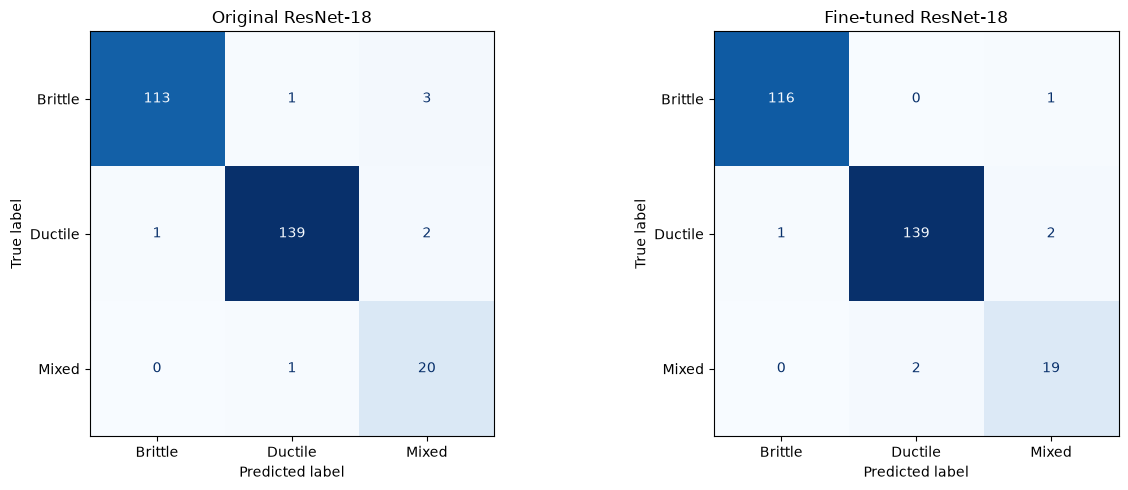


COMPARISON OF ERRORS
--------------------------------------------------
Errors corrected by fine-tuning: 3
New errors introduced: 1

CORRECTED IMAGES
304_H2_03_4.png | Actual: Brittle | Original: Mixed | Fine-tuned: Brittle
304_H2_04_6.png | Actual: Brittle | Original: Mixed | Fine-tuned: Brittle
X65_H2_12_1.png | Actual: Brittle | Original: Ductile | Fine-tuned: Brittle

NEW ERRORS
mX65_H2_26_29.png | Actual: Mixed | Fine-tuned: Ductile

Comparison saved to: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet18_finetune/plots


In [6]:

import matplotlib.pyplot as plt
from torchvision import models
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

# 1. Load original baseline model
baseline_model = models.resnet18(weights=None)

baseline_model.fc = torch.nn.Linear(
    baseline_model.fc.in_features, 3
)

baseline_checkpoint = torch.load(
    BASELINE_MODEL,
    map_location="cpu",
    weights_only=True
)

baseline_model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)

baseline_model = baseline_model.to(DEVICE)
baseline_model.eval()

# Fine-tuned model is already loaded from Cell 5
model.eval()

# 2. Evaluation function
def evaluate_model(net, loader):

    actual = []
    predicted = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(DEVICE)

            outputs = net(images)
            preds = outputs.argmax(dim=1)

            actual.extend(labels.tolist())
            predicted.extend(preds.cpu().tolist())

    return actual, predicted

# 3. Evaluate both models
y_true, baseline_preds = evaluate_model(
    baseline_model, val_loader
)

y_true_ft, finetuned_preds = evaluate_model(
    model, val_loader
)

assert y_true == y_true_ft
assert len(y_true) == len(val_records)

# 4. Print classification reports
for name, predictions in [
    ("ORIGINAL RESNET-18", baseline_preds),
    ("FINE-TUNED RESNET-18", finetuned_preds)
]:

    print(f"\n{name}")
    print("-" * 50)

    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

# 5. Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, predictions in zip(
    axes,
    ["Original ResNet-18", "Fine-tuned ResNet-18"],
    [baseline_preds, finetuned_preds]
):

    cm = confusion_matrix(
        y_true, predictions, labels=[0, 1, 2]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "baseline_vs_finetuned.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 6. Identify corrected and newly introduced errors
corrected = []
new_errors = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):

    if before != actual and after == actual:
        corrected.append(i)

    elif before == actual and after != actual:
        new_errors.append(i)

print("\nCOMPARISON OF ERRORS")
print("-" * 50)

print("Errors corrected by fine-tuning:", len(corrected))
print("New errors introduced:", len(new_errors))

print("\nCORRECTED IMAGES")
for i in corrected:
    print(
        val_records[i]["filename"],
        "| Actual:", CLASSES[y_true[i]],
        "| Original:", CLASSES[baseline_preds[i]],
        "| Fine-tuned:", CLASSES[finetuned_preds[i]]
    )

print("\nNEW ERRORS")
for i in new_errors:
    print(
        val_records[i]["filename"],
        "| Actual:", CLASSES[y_true[i]],
        "| Fine-tuned:", CLASSES[finetuned_preds[i]]
    )

print("\nComparison saved to:", PLOTS_DIR)


Corrected errors: 3
New errors: 1
Changed but still incorrect: 0

Total changed predictions: 4


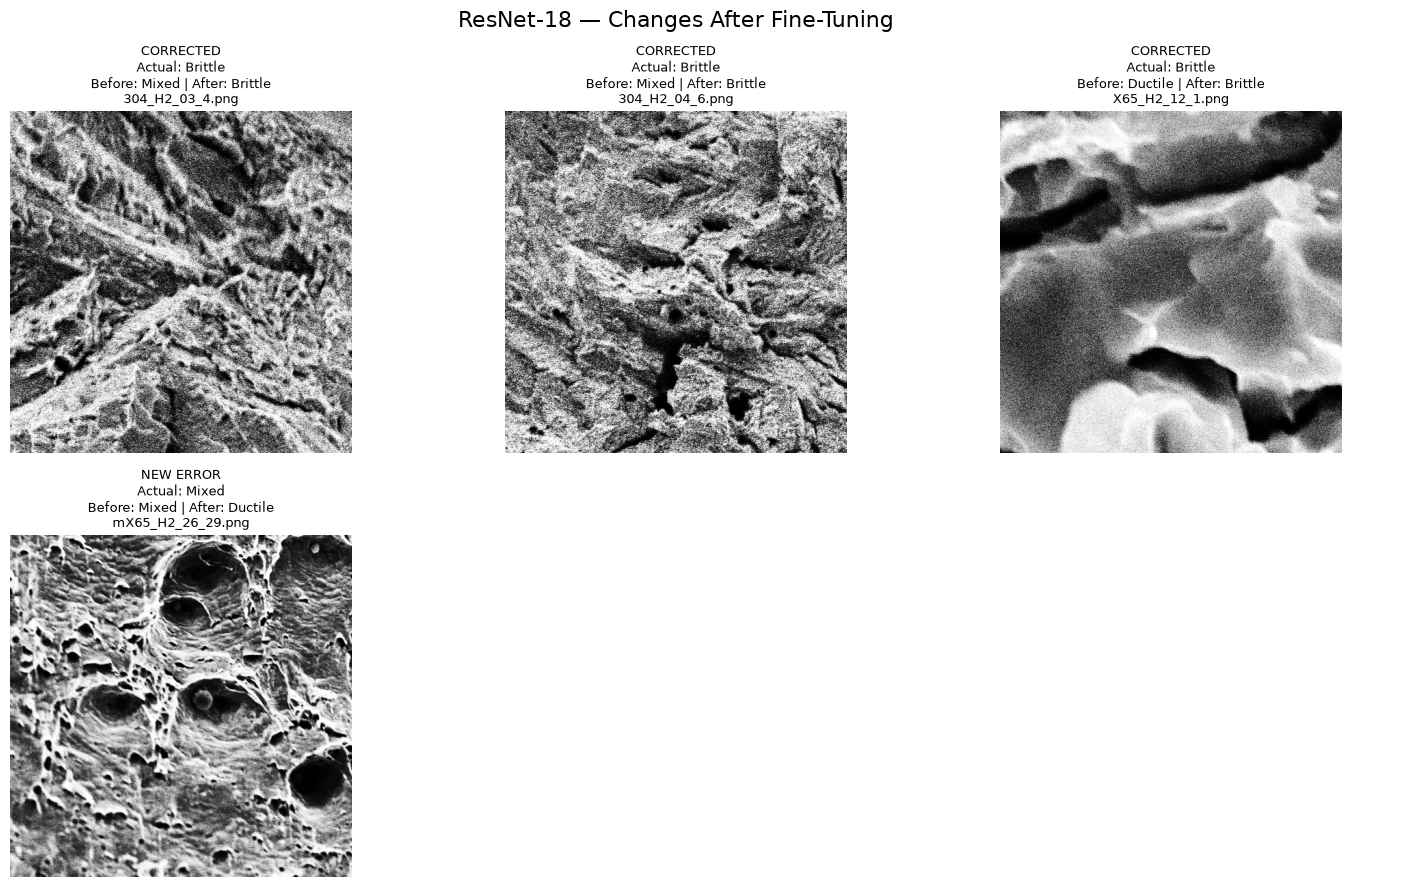

In [7]:

import math
import matplotlib.pyplot as plt
from PIL import Image

# 1. Compare predictions image by image
corrected = []
new_errors = []
changed_but_still_wrong = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):
    if before != actual and after == actual:
        corrected.append(i)

    elif before == actual and after != actual:
        new_errors.append(i)

    elif before != after and before != actual and after != actual:
        changed_but_still_wrong.append(i)

print("Corrected errors:", len(corrected))
print("New errors:", len(new_errors))
print("Changed but still incorrect:", len(changed_but_still_wrong))

# 2. Collect all changed predictions
changed_indices = [
    i for i in range(len(y_true))
    if baseline_preds[i] != finetuned_preds[i]
]

print("\nTotal changed predictions:", len(changed_indices))

# 3. Display the changed SEM images
if changed_indices:

    n_cols = 3
    n_rows = math.ceil(len(changed_indices) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 4.5 * n_rows),
        squeeze=False
    )

    for plot_idx, i in enumerate(changed_indices):

        row = val_records[i]

        path = DATA_DIR / row["label"] / row["filename"]

        with Image.open(path) as img:
            image = img.convert("L").copy()

        actual = CLASSES[y_true[i]]
        before = CLASSES[baseline_preds[i]]
        after = CLASSES[finetuned_preds[i]]

        if i in corrected:
            status = "CORRECTED"
        elif i in new_errors:
            status = "NEW ERROR"
        else:
            status = "STILL INCORRECT"

        ax = axes.flat[plot_idx]
        ax.imshow(image, cmap="gray")

        ax.set_title(
            f"{status}\n"
            f"Actual: {actual}\n"
            f"Before: {before} | After: {after}\n"
            f"{row['filename']}",
            fontsize=9
        )

        ax.axis("off")

    # Hide unused axes
    for ax in axes.flat[len(changed_indices):]:
        ax.axis("off")

    plt.suptitle(
        "ResNet-18 — Changes After Fine-Tuning",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / "finetuning_prediction_changes.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No predictions changed.")


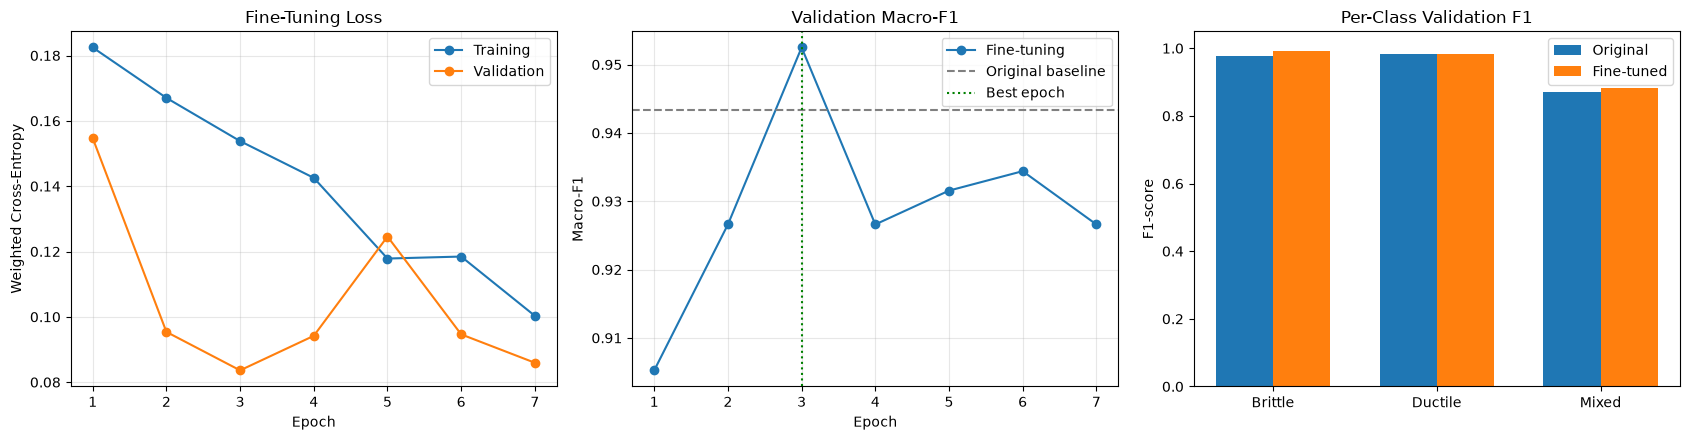

EXPERIMENT COMPLETED
---------------------------------------------
Original accuracy:  0.9714
Fine-tuned accuracy: 0.9786

Original Macro-F1:  0.9434
Fine-tuned Macro-F1: 0.9525

Best fine-tuning epoch: 3
Corrected errors: 3
New errors: 1

Saved:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet18_finetune/plots/finetuning_summary.png
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet18_finetune/experiment_summary.json


In [8]:

import json
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

# 1. Calculate metrics for both models
baseline_accuracy = accuracy_score(y_true, baseline_preds)
finetuned_accuracy = accuracy_score(y_true, finetuned_preds)

baseline_class_f1 = f1_score(
    y_true, baseline_preds,
    labels=[0, 1, 2],
    average=None
)

finetuned_class_f1 = f1_score(
    y_true, finetuned_preds,
    labels=[0, 1, 2],
    average=None
)

# 2. Create experiment plots
epochs = range(1, len(history_ft["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot A: Training and validation loss
axes[0].plot(
    epochs, history_ft["train_loss"],
    marker="o", label="Training"
)
axes[0].plot(
    epochs, history_ft["val_loss"],
    marker="o", label="Validation"
)
axes[0].set_title("Fine-Tuning Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted Cross-Entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot B: Macro-F1 improvement
axes[1].plot(
    epochs, history_ft["val_macro_f1"],
    marker="o", label="Fine-tuning"
)
axes[1].axhline(
    baseline_f1,
    linestyle="--", color="gray",
    label="Original baseline"
)
axes[1].axvline(
    best_epoch,
    linestyle=":", color="green",
    label="Best epoch"
)
axes[1].set_title("Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Plot C: Per-class F1 comparison
x = np.arange(len(CLASSES))
width = 0.35

axes[2].bar(
    x - width/2, baseline_class_f1,
    width, label="Original"
)
axes[2].bar(
    x + width/2, finetuned_class_f1,
    width, label="Fine-tuned"
)
axes[2].set_xticks(x)
axes[2].set_xticklabels(CLASSES)
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Per-Class Validation F1")
axes[2].set_ylabel("F1-score")
axes[2].legend()

plt.tight_layout()

plot_path = PLOTS_DIR / "finetuning_summary.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

# 3. Save structured experiment results
summary = {
    "experiment": "ResNet18_Progressive_FineTuning",
    "architecture": "ResNet-18",
    "initialization": "Previous SEM-trained checkpoint",
    "unfrozen_layers": ["layer4.1", "fc"],
    "trainable_parameters": 4722179,
    "learning_rates": {
        "layer4.1": 1e-5,
        "fc": 1e-4
    },
    "dataset": {
        "train": len(train_records),
        "validation": len(val_records),
        "test": len(test_records)
    },
    "baseline": {
        "accuracy": baseline_accuracy,
        "macro_f1": float(baseline_f1),
        "class_f1": baseline_class_f1.tolist()
    },
    "fine_tuned": {
        "accuracy": finetuned_accuracy,
        "macro_f1": float(best_f1),
        "class_f1": finetuned_class_f1.tolist(),
        "best_epoch": best_epoch,
        "epochs_run": len(history_ft["train_loss"])
    },
    "prediction_changes": {
        "corrected": [
            val_records[i]["filename"] for i in corrected
        ],
        "new_errors": [
            val_records[i]["filename"] for i in new_errors
        ]
    },
    "history": history_ft,
    "test_evaluated": False,
    "note": (
        "Validation uses provisional filename-based groups. "
        "Physical specimen independence is not verified."
    )
}

summary_path = RESULTS_DIR / "experiment_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

# 4. Print final results
print("EXPERIMENT COMPLETED")
print("-" * 45)

print(f"Original accuracy:  {baseline_accuracy:.4f}")
print(f"Fine-tuned accuracy: {finetuned_accuracy:.4f}")

print(f"\nOriginal Macro-F1:  {baseline_f1:.4f}")
print(f"Fine-tuned Macro-F1: {best_f1:.4f}")

print(f"\nBest fine-tuning epoch: {best_epoch}")
print(f"Corrected errors: {len(corrected)}")
print(f"New errors: {len(new_errors)}")

print("\nSaved:")
print(plot_path)
print(summary_path)
